# 03 - San Diego: out of possession
1. Side of attack
2. Pressing
3. Block height (SkillCorner)

## Setup

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from mplsoccer import VerticalPitch

pd.set_option("display.max_columns", 50)

In [2]:
PROCESSED_FOLDER = Path("../../data/processed")
FIGURES_FOLDER = Path("../../figures")

# colours
SD_COLOR = "#2a78d6"          # San Diego = blue
OPPONENT_COLOR = "#eb6834"    # opponents = orange
NASHVILLE_COLOR = "#eda100"   # Nashville = gold, same as the other notebooks
BACKGROUND = "#fcfcfb"
LINE_COLOR = "#9a9890"
TEXT_COLOR = "#0b0b0b"
TEXT_MUTED = "#52514e"

In [3]:
events = pd.read_parquet(PROCESSED_FOLDER / "sb_events.parquet")
matches = pd.read_parquet(PROCESSED_FOLDER / "matches.parquet")
dynamic_events = pd.read_parquet(PROCESSED_FOLDER / "sc_dynamic.parquet")

sd_match_events = events[events["focus_team"] == "San Diego"]
is_sd_action = sd_match_events["team"] == "San Diego FC"
sd_own_events = sd_match_events[is_sd_action]
opponent_events_vs_sd = sd_match_events[~is_sd_action]

number_of_matches = sd_match_events["match_id"].nunique()
print("San Diego matches:", number_of_matches)

San Diego matches: 24


In [4]:
# chart formatting
def style_axis(ax):
    ax.set_facecolor(BACKGROUND)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.tick_params(colors=TEXT_MUTED)

## 1 - Side of attack
Final-third entry = completed pass or carry crossing x = 80.
Opponent's left (y < 26.7) = San Diego's right.

In [5]:
def side_from_sd_view(opponent_y):
    if opponent_y < 80 / 3:
        return "SD right"       # opponent's left = San Diego's right
    elif opponent_y < 2 * 80 / 3:
        return "Centre"
    else:
        return "SD left"        # opponent's right = San Diego's left

In [6]:
is_pass_or_carry = opponent_events_vs_sd["type"].isin(["Pass", "Carry"])
starts_before_final_third = opponent_events_vs_sd["x"] < 80
ends_in_final_third = opponent_events_vs_sd["end_x"] >= 80

entries = opponent_events_vs_sd[is_pass_or_carry & starts_before_final_third & ends_in_final_third]

# carries + completed passes (empty pass_outcome = completed)
is_carry = entries["type"] == "Carry"
is_completed_pass = entries["pass_outcome"].isna()
entries = entries[is_carry | is_completed_pass].copy()

entries["sd_side"] = entries["end_y"].apply(side_from_sd_view)
entry_share = entries["sd_side"].value_counts(normalize=True)
print("Opponent final-third entries per game:", round(len(entries) / number_of_matches, 1))
entry_share.round(2)

Opponent final-third entries per game: 34.1


sd_side
SD left     0.42
SD right    0.35
Centre      0.23
Name: proportion, dtype: float64

### Entries by side
Drawn from San Diego's defending view (opponents attack upwards).

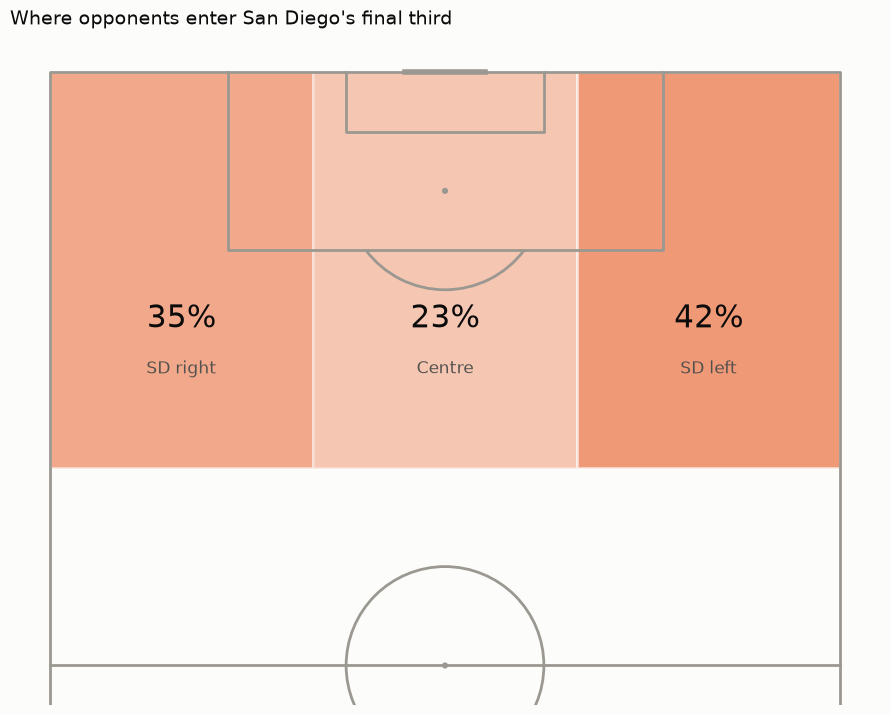

In [7]:
pitch = VerticalPitch(pitch_type="statsbomb", half=True, pitch_color=BACKGROUND, line_color=LINE_COLOR, line_zorder=2)
fig, ax = pitch.draw(figsize=(9, 8))
fig.set_facecolor(BACKGROUND)

# (y from, y to, label)
lanes = [
    (0, 80 / 3, "SD right"),
    (80 / 3, 2 * 80 / 3, "Centre"),
    (2 * 80 / 3, 80, "SD left"),
]

for y_from, y_to, label in lanes:
    share = entry_share[label]
    # VerticalPitch: horizontal axis = y
    lane_box = Rectangle((y_from, 80), y_to - y_from, 40, facecolor=OPPONENT_COLOR, alpha=share * 1.6,
                         edgecolor=BACKGROUND, linewidth=2, zorder=1)
    ax.add_patch(lane_box)
    ax.text((y_from + y_to) / 2, 95, f"{share:.0%}", ha="center", va="center", fontsize=22, color=TEXT_COLOR)
    ax.text((y_from + y_to) / 2, 90, label, ha="center", va="center", fontsize=12, color=TEXT_MUTED)

ax.set_title("Where opponents enter San Diego's final third", fontsize=14, color=TEXT_COLOR, loc="left")
fig.savefig(FIGURES_FOLDER / "ex1_opponent_entries_by_side.png", dpi=200, bbox_inches="tight")
plt.show()

### What happens after they get in
Each opponent possession is grouped by the side of its first entry into San Diego's final third. Then the xG and goals of that possession (no penalties).

In [8]:
first_entries = entries.sort_values(["match_id", "index"]).drop_duplicates(["match_id", "possession"])

is_shot = (opponent_events_vs_sd["type"] == "Shot") & (opponent_events_vs_sd["shot_type"] != "Penalty")
opponent_shots_np = opponent_events_vs_sd[is_shot].copy()
opponent_shots_np["goal"] = opponent_shots_np["shot_outcome"] == "Goal"
possession_outcome = opponent_shots_np.groupby(["match_id", "possession"]).agg(
    xG=("shot_statsbomb_xg", "sum"), goals=("goal", "sum")).reset_index()

first_entries = first_entries.merge(possession_outcome, on=["match_id", "possession"], how="left")
first_entries["xG"] = first_entries["xG"].fillna(0)
first_entries["goals"] = first_entries["goals"].fillna(0)

entry_outcome = first_entries.groupby("sd_side").agg(possessions=("xG", "size"), xG=("xG", "sum"), goals=("goals", "sum"))
entry_outcome["xG per 100 entries"] = entry_outcome["xG"] / entry_outcome["possessions"] * 100
entry_outcome = entry_outcome.loc[["SD left", "Centre", "SD right"]]
entry_outcome.round(2)


,possessions,xG,goals,xG per 100 entries
sd_side,,,,
SD left,269,7.10,9.0,2.64
Centre,158,7.20,8.0,4.56
SD right,220,2.45,0.0,1.11


In [9]:
# who gets the ball into San Diego's left side (opponent positions)
entries[entries["sd_side"] == "SD left"]["position"].value_counts().head(5)


position
Right Back                   64
Right Center Back            59
Right Wing                   34
Center Attacking Midfield    28
Left Defensive Midfield      24
Name: count, dtype: int64

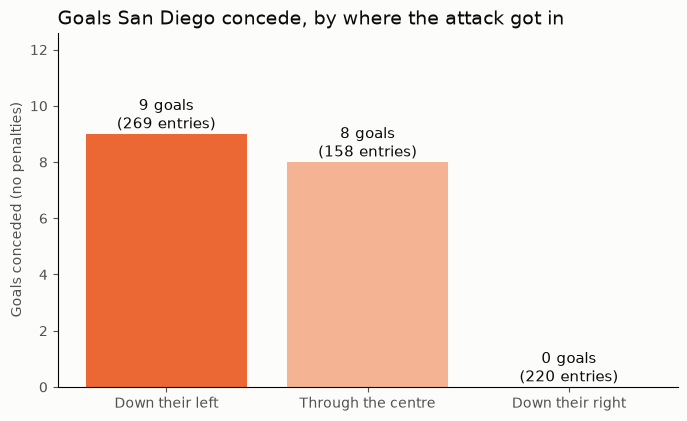

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.6))
fig.set_facecolor(BACKGROUND)
style_axis(ax)

bar_colors = [OPPONENT_COLOR, "#f4b393", "#f4b393"]
ax.bar(["Down their left", "Through the centre", "Down their right"], entry_outcome["goals"], color=bar_colors)

for position, (side, row) in enumerate(entry_outcome.iterrows()):
    label = f"{row['goals']:.0f} goals\n({row['possessions']:.0f} entries)"
    ax.text(position, row["goals"] + 0.2, label, ha="center", fontsize=11, color=TEXT_COLOR)

ax.set_ylim(0, entry_outcome["goals"].max() * 1.4)
ax.set_ylabel("Goals conceded (no penalties)", color=TEXT_MUTED)
ax.set_title("Goals San Diego concede, by where the attack got in", fontsize=14, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex1_entries_outcome_by_side.png", dpi=200, bbox_inches="tight")
plt.show()


Attacks that get in down San Diego's left produced 9 goals, down their right none. The entries come mostly from the opponents' right-back and right centre-back.

## 2 - Pressing: PPDA
Opponent passes in their own 60% ÷ San Diego tackles, interceptions and fouls there. Lower = more pressing.
Opponent's own 60% = x > 48 in the defending team's data.

In [11]:
def ppda(pressing_team_events, passing_team_events):
    # passes in their own 60%
    is_pass = passing_team_events["type"] == "Pass"
    in_own_60 = passing_team_events["x"] < 72
    passes_allowed = (is_pass & in_own_60).sum()

    # defensive actions in the opponent's 60% (x > 48)
    is_tackle = (pressing_team_events["type"] == "Duel") & (pressing_team_events["duel_type"] == "Tackle")
    is_interception = pressing_team_events["type"] == "Interception"
    is_foul = pressing_team_events["type"] == "Foul Committed"
    in_opponent_60 = pressing_team_events["x"] > 48
    defensive_actions = ((is_tackle | is_interception | is_foul) & in_opponent_60).sum()

    return passes_allowed / defensive_actions

In [12]:
print("San Diego PPDA:", round(ppda(sd_own_events, opponent_events_vs_sd), 1))

San Diego PPDA: 15.4


### Pressing by game state and by period
Game state = the score at the moment of each event.

In [13]:
def add_game_state(match_events, team_name):
    match_events = match_events.sort_values(["match_id", "index"]).copy()

    is_shot_goal = (match_events["type"] == "Shot") & (match_events["shot_outcome"] == "Goal")
    is_own_goal = match_events["type"] == "Own Goal For"
    is_goal = is_shot_goal | is_own_goal
    is_team = match_events["team"] == team_name

    # +1 for a goal for, -1 for a goal against
    match_events["goal_value"] = 0
    match_events.loc[is_goal & is_team, "goal_value"] = 1
    match_events.loc[is_goal & ~is_team, "goal_value"] = -1

    # goal difference before the event (the goal itself counts from the next event)
    running_total = match_events.groupby("match_id")["goal_value"].cumsum()
    goal_difference = running_total - match_events["goal_value"]

    match_events["game_state"] = "Level"
    match_events.loc[goal_difference > 0, "game_state"] = "Leading"
    match_events.loc[goal_difference < 0, "game_state"] = "Trailing"
    return match_events

In [14]:
sd_match_events_with_state = add_game_state(sd_match_events, "San Diego FC")

ppda_by_state = {}
for state in ["Leading", "Level", "Trailing"]:
    in_state = sd_match_events_with_state[sd_match_events_with_state["game_state"] == state]
    sd_part = in_state[in_state["team"] == "San Diego FC"]
    opponent_part = in_state[in_state["team"] != "San Diego FC"]
    ppda_by_state[state] = ppda(sd_part, opponent_part)

pd.Series(ppda_by_state).round(1)      # lower = more pressing


Leading     15.7
Level       16.1
Trailing    13.9
dtype: float64

In [15]:
minute_band = pd.cut(sd_match_events["minute"], bins=[0, 30, 60, 75, 130], labels=["0-30", "30-60", "60-75", "75+"], right=False)

ppda_by_period = {}
for band in ["0-30", "30-60", "60-75", "75+"]:
    in_band = sd_match_events[minute_band == band]
    sd_part = in_band[in_band["team"] == "San Diego FC"]
    opponent_part = in_band[in_band["team"] != "San Diego FC"]
    ppda_by_period[band] = ppda(sd_part, opponent_part)

pd.Series(ppda_by_period).round(1)


0-30     15.2
30-60    15.9
60-75    15.3
75+      15.2
dtype: float64

They press hardest when behind (PPDA 13.9, against 15.7 when leading), and the press does not fade late in games (about 15 in every period).

### Where they press and win the ball
Pressures by third, with Nashville as a benchmark. Then what happens after San Diego win the ball in the final third (open-play possession that starts there).

In [16]:
def pressure_shares(focus_team, team_name):
    own_events = events[(events["focus_team"] == focus_team) & (events["team"] == team_name)]
    pressures = own_events[own_events["type"] == "Pressure"]
    thirds = pd.cut(pressures["x"], bins=[0, 40, 80, 120], labels=["Own third", "Middle third", "Opponent's third"], include_lowest=True)
    return thirds.value_counts(normalize=True).sort_index() * 100


sd_shares = pressure_shares("San Diego", "San Diego FC")
nashville_shares = pressure_shares("Nashville", "Nashville SC")
pd.DataFrame({"San Diego": sd_shares, "Nashville": nashville_shares}).round(0)

,San Diego,Nashville
x,,
Own third,27.0,31.0
Middle third,38.0,44.0
Opponent's third,35.0,25.0


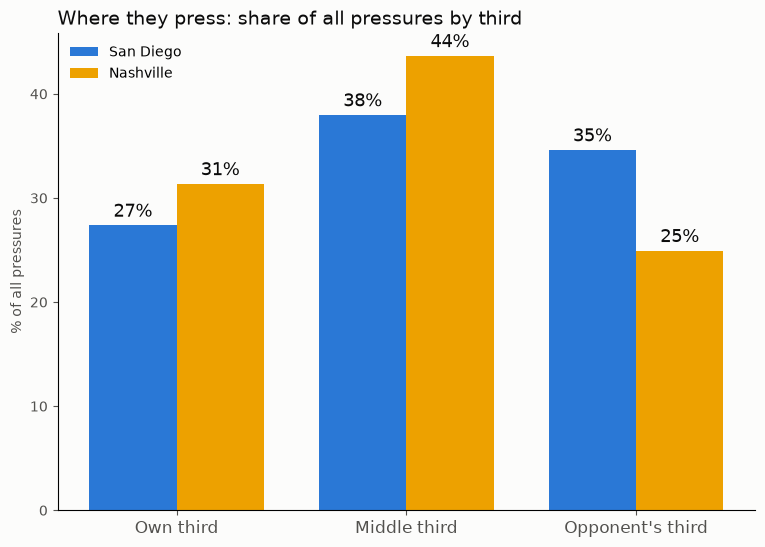

In [17]:
positions = np.arange(len(sd_shares))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(9, 6.2))
fig.set_facecolor(BACKGROUND)
style_axis(ax)

sd_bars = ax.bar(positions - bar_width / 2, sd_shares.values, width=bar_width, color=SD_COLOR, label="San Diego")
nashville_bars = ax.bar(positions + bar_width / 2, nashville_shares.values, width=bar_width, color=NASHVILLE_COLOR, label="Nashville")
ax.bar_label(sd_bars, fmt="%.0f%%", fontsize=13, color=TEXT_COLOR, padding=3)
ax.bar_label(nashville_bars, fmt="%.0f%%", fontsize=13, color=TEXT_COLOR, padding=3)

ax.set_xticks(positions)
ax.set_xticklabels(["Own third", "Middle third", "Opponent's third"], fontsize=12)
ax.set_ylabel("% of all pressures", color=TEXT_MUTED)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Where they press: share of all pressures by third", fontsize=14, color=TEXT_COLOR, loc="left")

fig.savefig(FIGURES_FOLDER / "ex1_sd_pressing_zones.png", dpi=200, bbox_inches="tight")
plt.show()

In [18]:
# first action of each San Diego open-play possession
sd_possession_events = sd_own_events[sd_own_events["possession_team"] == "San Diego FC"]
open_play = sd_possession_events[sd_possession_events["play_pattern"] == "Regular Play"]
first_actions = open_play.sort_values(["match_id", "index"]).drop_duplicates(["match_id", "possession"])

# possessions won in the final third
won_high = first_actions[first_actions["x"] >= 80][["match_id", "possession"]]

sd_shots = sd_own_events[sd_own_events["type"] == "Shot"]
shots_after_high_win = sd_shots.merge(won_high, on=["match_id", "possession"])
goals_after_high_win = (shots_after_high_win["shot_outcome"] == "Goal").sum()

print("Balls won in the final third per game:", round(len(won_high) / number_of_matches, 1))
print("Shots after winning it there:", len(shots_after_high_win), "| goals:", goals_after_high_win)

Balls won in the final third per game: 6.6
Shots after winning it there: 41 | goals: 9


35% of San Diego's pressures are in the final third (Nashville 25%). They win the ball there 6.6 times a game, and those possessions led to 41 shots and 9 goals.

## 3 - Block height (SkillCorner)
Opponent possession time split by San Diego's block: high, medium or low.

In [19]:
dynamic_events[["match_id", "team_shortname", "event_type", "duration",
                "team_in_possession_phase_type", "team_out_of_possession_phase_type"]].head()

,match_id,team_shortname,event_type,duration,team_in_possession_phase_type,team_out_of_possession_phase_type
0,2004842,New England,player_possession,2.1,create,medium_block
1,2004842,New England,passing_option,2.1,create,medium_block
2,2004842,New England,passing_option,1.9,create,medium_block
3,2004842,New England,player_possession,1.1,create,medium_block
4,2004842,New England,passing_option,0.4,create,medium_block


In [20]:
# SD SkillCorner match IDs
sd_sc_match_ids = matches[matches["focus_team"] == "San Diego"]["sc_match_id"]

in_sd_match = dynamic_events["match_id"].isin(sd_sc_match_ids)
is_possession = dynamic_events["event_type"] == "player_possession"
is_opponent = dynamic_events["team_shortname"] != "San Diego"      # team_shortname = team with the ball
opponent_possessions = dynamic_events[in_sd_match & is_possession & is_opponent]

In [21]:
# share of time in each phase while the opponent has the ball
seconds_per_phase = opponent_possessions.groupby("team_out_of_possession_phase_type")["duration"].sum()
block_share = seconds_per_phase / seconds_per_phase.sum() * 100
block_share.sort_values(ascending=False).round(1)

team_out_of_possession_phase_type
medium_block             39.2
high_block               21.8
low_block                21.5
defending_transition      5.3
chaotic                   4.6
defending_direct          3.8
defending_quick_break     1.8
defending_set_play        1.3
disruption                0.8
Name: duration, dtype: float64

Medium block 39% of the time, high 22%, low 22%.